In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load practice dataset
df = sns.load_dataset("tips")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
display(df.head())

Dataset loaded successfully!
Dataset shape: (244, 7)


,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


In [2]:
print("Dataset information:")
df.info()

print("\nSummary statistics:")
display(df.describe().round(2))

print("\nMissing values:")
display(df.isnull().sum())

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 244 entries, 0 to 243
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype   
---  ------      --------------  -----   
 0   total_bill  244 non-null    float64 
 1   tip         244 non-null    float64 
 2   sex         244 non-null    category
 3   smoker      244 non-null    category
 4   day         244 non-null    category
 5   time        244 non-null    category
 6   size        244 non-null    int64   
dtypes: category(4), float64(2), int64(1)
memory usage: 7.4 KB

Summary statistics:


,total_bill,tip,size
count,244.00,244.00,244.00
mean,19.79,3.00,2.57
std,8.90,1.38,0.95
min,3.07,1.00,1.00
25%,13.35,2.00,2.00
50%,17.80,2.90,2.00
75%,24.13,3.56,3.00
max,50.81,10.00,6.00



Missing values:


total_bill    0
tip           0
sex           0
smoker        0
day           0
time          0
size          0
dtype: int64

### 1. Histogram

**Why selected:** A histogram helps examine the distribution of restaurant bills and identify concentration, skewness, and potential extreme values.

**Interpretation:** The histogram shows how frequently different total bill amounts occur.

**Insight obtained:** The shape of the distribution helps identify typical bill ranges and whether the data is approximately symmetric or skewed.

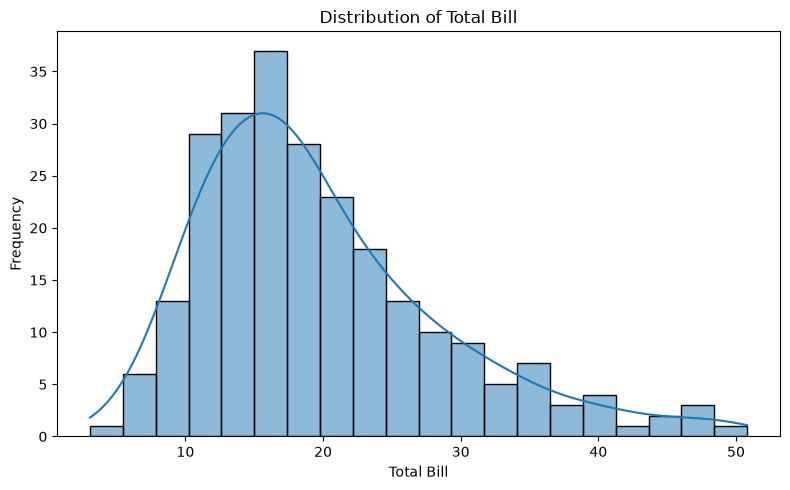

In [3]:
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x="total_bill", bins=20, kde=True)

plt.title("Distribution of Total Bill")
plt.xlabel("Total Bill")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

### 2. Box Plot

**Why selected:** A box plot summarizes the spread of restaurant bills and highlights potential outliers.

**Interpretation:** The box represents the middle 50% of observations, the line inside the box is the median, and points beyond the whiskers may be potential outliers.

**Insight obtained:** The plot helps identify variability and unusually high or low bill amounts that may require investigation.

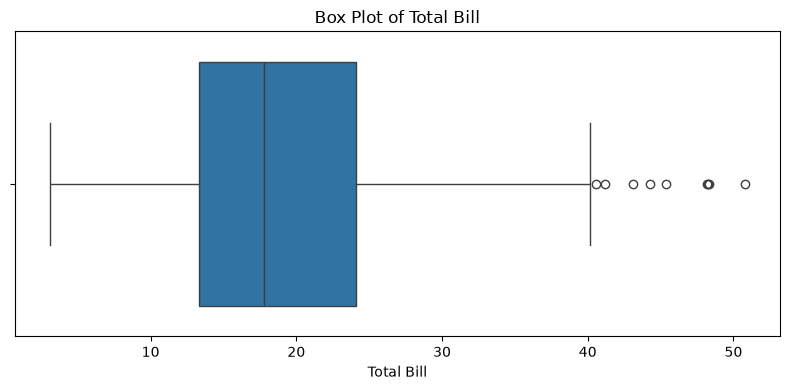

In [4]:
plt.figure(figsize=(8, 4))
sns.boxplot(data=df, x="total_bill")

plt.title("Box Plot of Total Bill")
plt.xlabel("Total Bill")
plt.tight_layout()
plt.show()

### 3. Bar Chart

**Why selected:** A bar chart compares the average tip amount across days of the week.

**Interpretation:** Each bar represents the average tip for a particular day.

**Insight obtained:** Differences in bar heights reveal which days have higher or lower average tips in this dataset. These differences describe an association and do not establish causation.

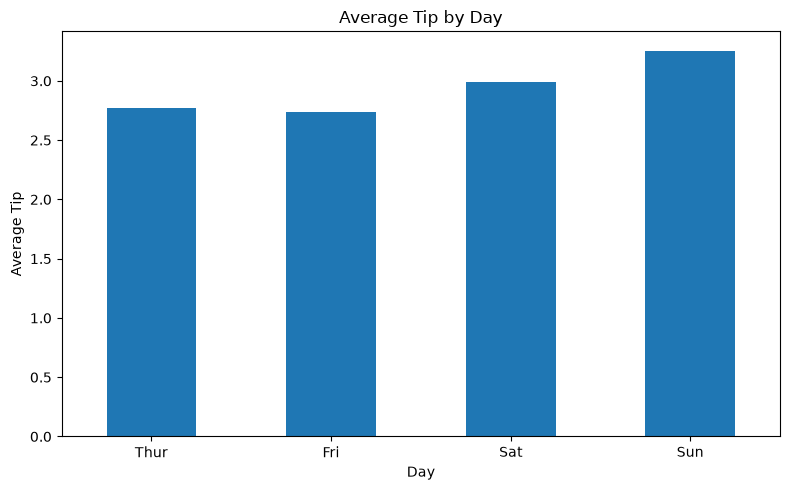

In [5]:
average_tip = df.groupby("day", observed=False)["tip"].mean()

average_tip.plot(kind="bar", figsize=(8, 5))

plt.title("Average Tip by Day")
plt.xlabel("Day")
plt.ylabel("Average Tip")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### 4. Count Plot

**Why selected:** A count plot helps compare how many restaurant visits occurred on each day.

**Interpretation:** Each bar represents the number of records for a particular day.

**Insight obtained:** The plot identifies the most and least frequently represented days in the dataset.

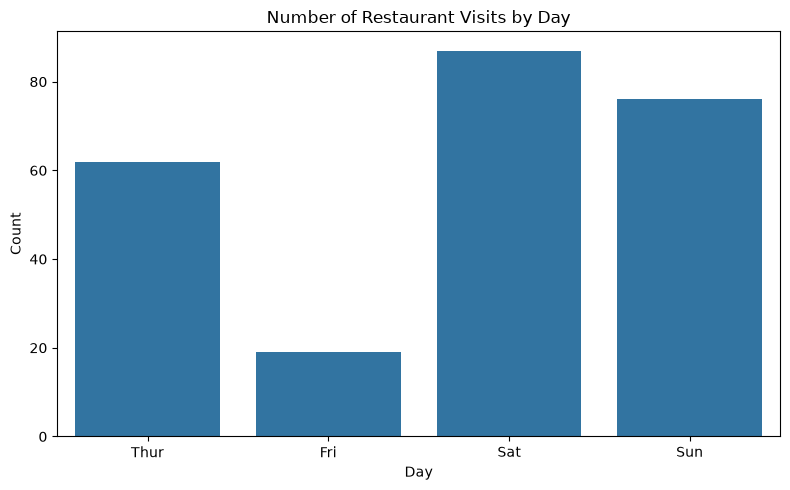

In [6]:
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="day")

plt.title("Number of Restaurant Visits by Day")
plt.xlabel("Day")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

### 5. Scatter Plot

**Why selected:** A scatter plot helps examine the relationship between the total bill and tip amount.

**Interpretation:** Each point represents one restaurant bill. The direction and spread of the points indicate whether larger bills tend to be associated with larger tips.

**Insight obtained:** The plot helps identify trends, variation, and potential unusual observations in the relationship between bills and tips.

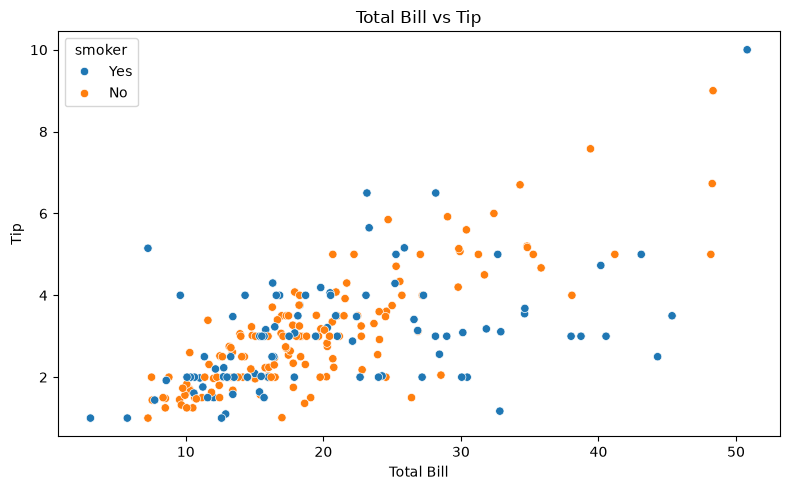

In [7]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="total_bill",
    y="tip",
    hue="smoker"
)

plt.title("Total Bill vs Tip")
plt.xlabel("Total Bill")
plt.ylabel("Tip")
plt.tight_layout()
plt.show()

### 6. Line Plot

**Why selected:** A line plot shows how tip amounts vary across the order of observations in the dataset.

**Interpretation:** Each point represents a tip amount, and the connecting lines show variation between consecutive records.

**Insight obtained:** The plot highlights fluctuations and unusually high or low tips. Because the dataset is not time-based, the line should not be interpreted as a time trend.

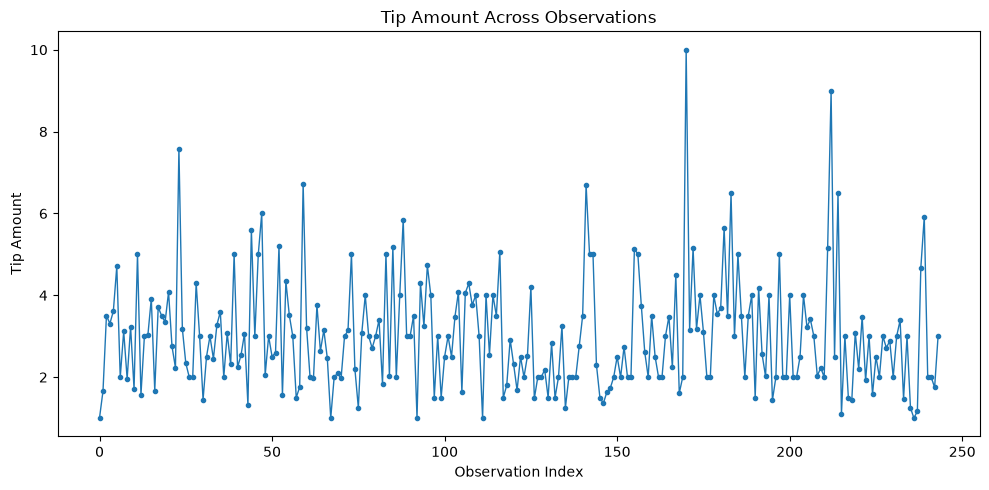

In [8]:
plt.figure(figsize=(10, 5))

plt.plot(df.index, df["tip"], marker=".", linewidth=1)

plt.title("Tip Amount Across Observations")
plt.xlabel("Observation Index")
plt.ylabel("Tip Amount")
plt.tight_layout()
plt.show()

### 7. Violin Plot

**Why selected:** A violin plot helps compare the distribution of tip amounts between different days.

**Interpretation:** The width of each violin indicates where observations are more concentrated. The plot also shows how the distributions differ across days.

**Insight obtained:** This visualization helps compare the typical tip amounts, spread, and distribution shapes across days.

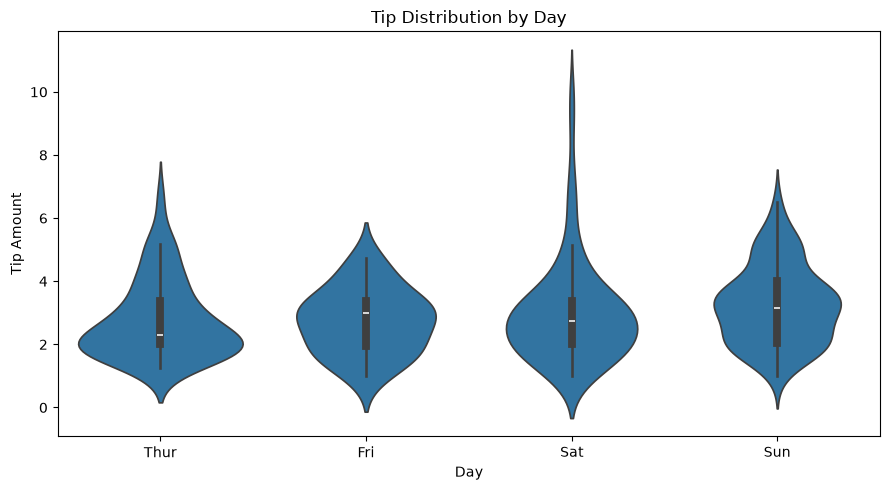

In [9]:
plt.figure(figsize=(9, 5))

sns.violinplot(data=df, x="day", y="tip")

plt.title("Tip Distribution by Day")
plt.xlabel("Day")
plt.ylabel("Tip Amount")
plt.tight_layout()
plt.show()

### 8. Pair Plot

**Why selected:** A pair plot helps explore relationships among total bill, tip, and party size.

**Interpretation:** The off-diagonal plots show pairwise relationships, while the diagonal plots show individual variable distributions.

**Insight obtained:** The pair plot helps identify possible associations, clusters, and unusual observations across numerical features.

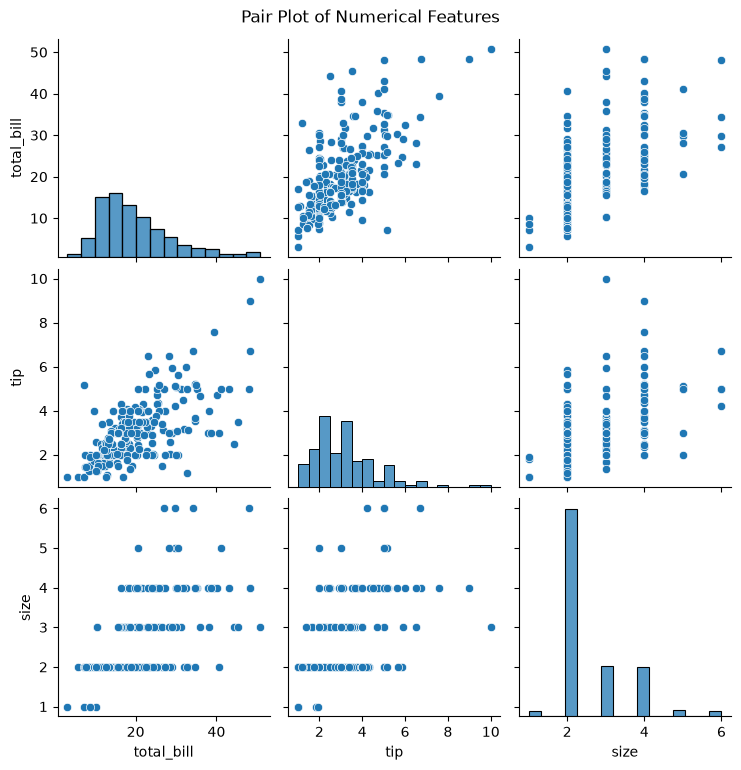

In [10]:
sns.pairplot(
    df[["total_bill", "tip", "size"]],
    diag_kind="hist"
)

plt.suptitle("Pair Plot of Numerical Features", y=1.02)
plt.show()

### 9. Heatmap

**Why selected:** A heatmap makes it easier to compare correlations between numerical features.

**Interpretation:** Correlation values range from -1 to +1. Values near +1 indicate strong positive linear relationships, values near -1 indicate strong negative linear relationships, and values near zero indicate weak linear relationships.

**Insight obtained:** The heatmap helps identify numerical features that move together, although correlation does not establish causation.

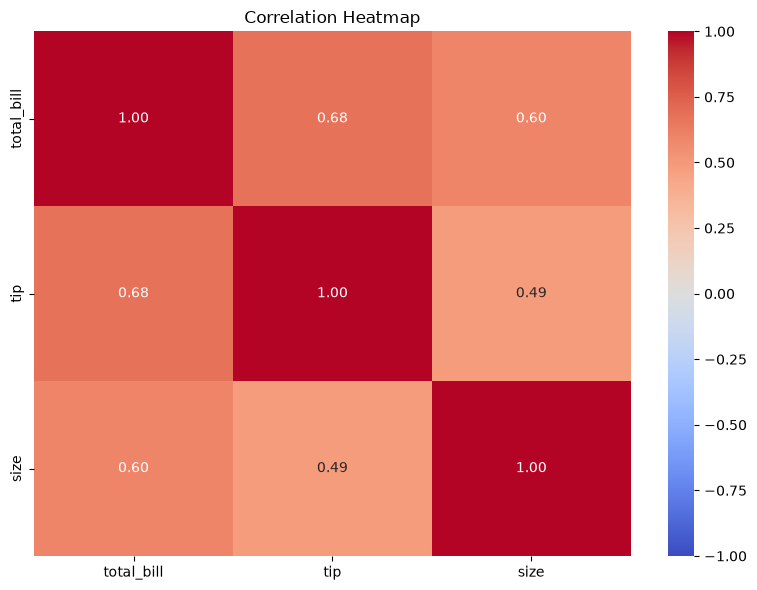

In [11]:
numerical_df = df.select_dtypes(include="number")
correlation_matrix = numerical_df.corr()

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

### 10. Distribution Plot

**Why selected:** A distribution plot helps investigate the shape of the total bill distribution.

**Interpretation:** The histogram shows the frequency of bill amounts, while the density curve provides a smoothed view of the distribution.

**Insight obtained:** The plot helps identify the most common ranges, possible skewness, and potential extreme values.

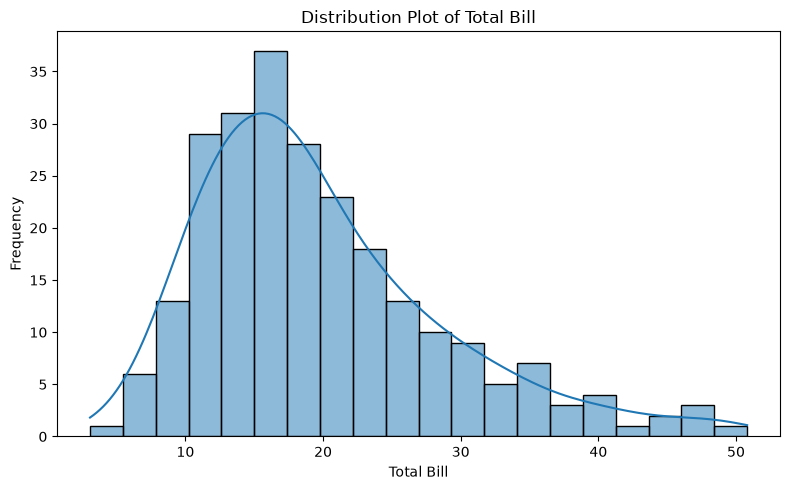

In [12]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="total_bill",
    kde=True,
    bins=20
)

plt.title("Distribution Plot of Total Bill")
plt.xlabel("Total Bill")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

## Conclusion

In this notebook, I used Matplotlib and Seaborn to create ten visualizations for exploratory data analysis: histogram, box plot, bar chart, count plot, scatter plot, line plot, violin plot, pair plot, heatmap, and distribution plot.

Each visualization was selected to answer a specific question about the dataset. The graphs helped examine numerical distributions, potential outliers, category frequencies, relationships between variables, and correlations. The insights support a better understanding of the data before further analysis or machine learning.

Visualizations should be interpreted in context, and conclusions should be based on the patterns actually observed rather than assumptions.